Importing plotly failed. Interactive plots will not work.


Total hourly records: 4320


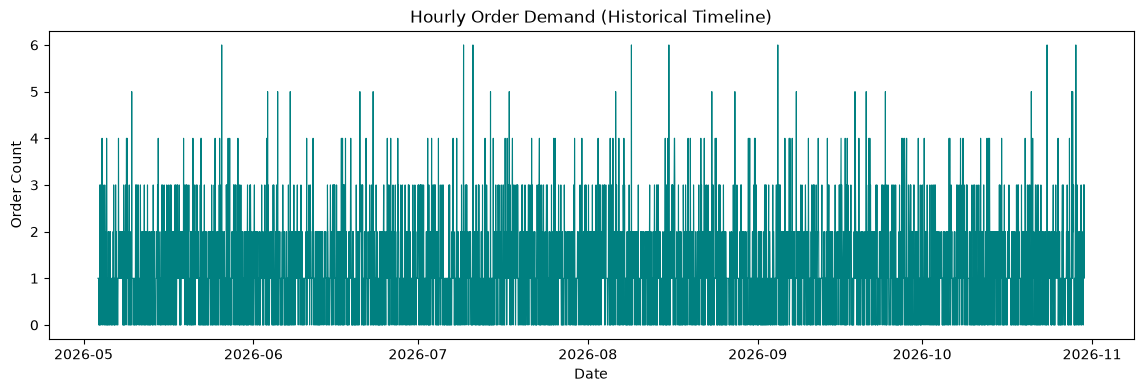

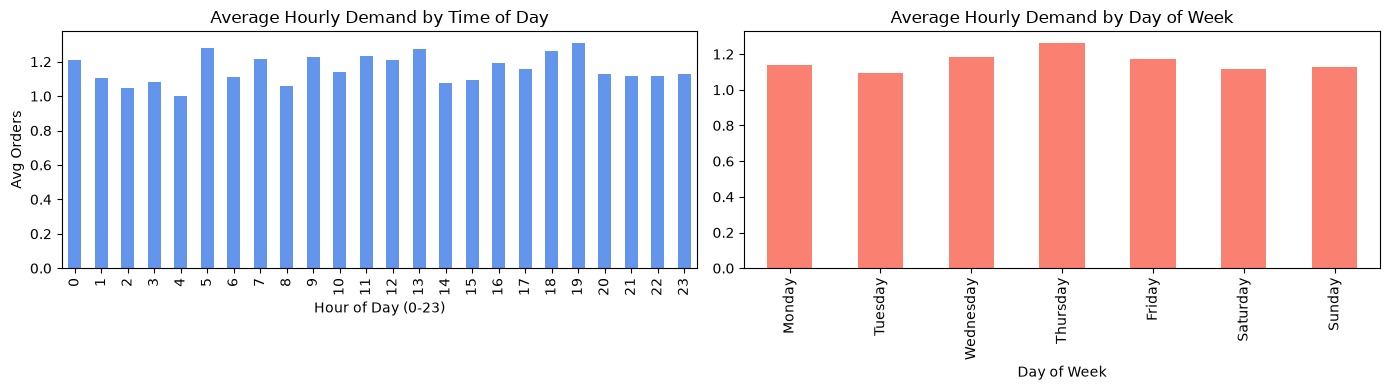

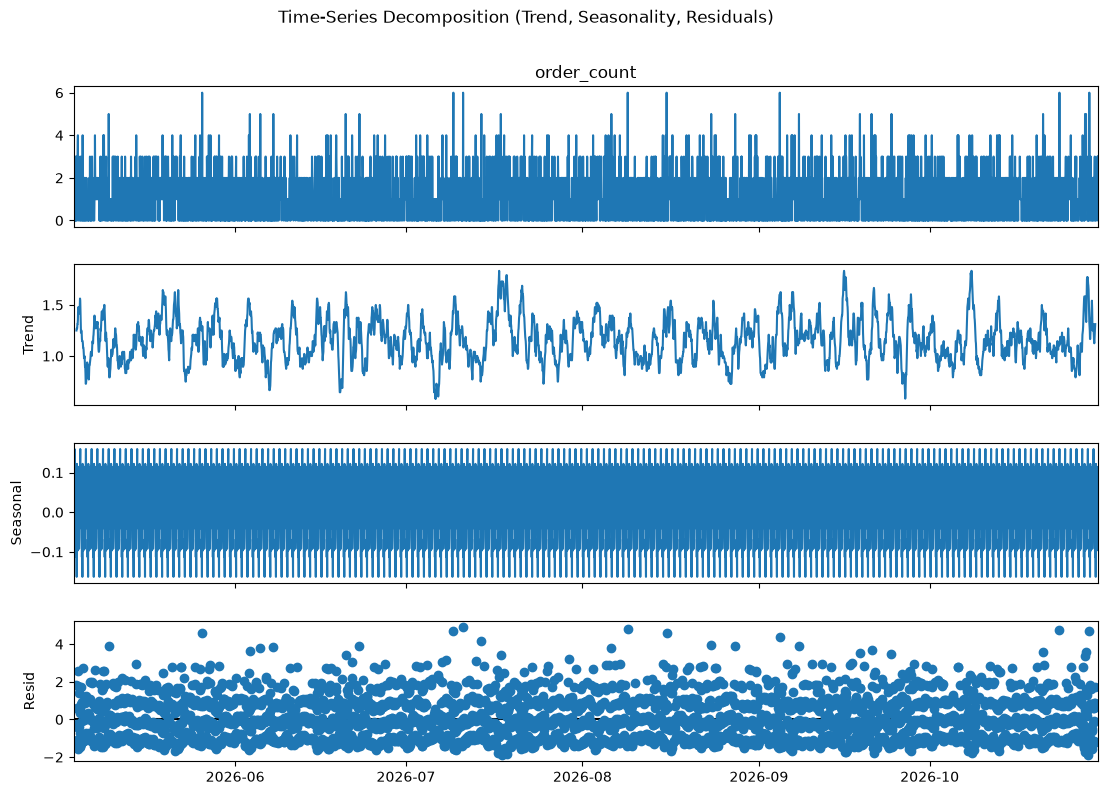

/tmp/ipykernel_16955/3144935978.py:59: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(hourly_demand['order_count'].dropna())
/home/nineleaps/Music/uber-eats-capstone/venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/nineleaps/Music/uber-eats-capstone/venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


--- ADF Test Results ---
ADF Statistic: -65.4927
p-value: 0.0000e+00
Critical Values: {'1%': np.float64(-3.4318649781908066), '5%': np.float64(-2.862209433310026), '10%': np.float64(-2.567126344149579)}
Conclusion: The series is stationary (p < 0.05). No differencing needed (d=0).
Train window: 2026-05-03 15:00:00 to 2026-10-16 14:00:00 (3984 hours)
Test window:  2026-10-16 15:00:00 to 2026-10-30 14:00:00 (336 hours)


/home/nineleaps/Music/uber-eats-capstone/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
15:40:51 - cmdstanpy - INFO - Chain [1] start processing
15:40:51 - cmdstanpy - INFO - Chain [1] done processing



--- Model Comparison on Test Horizon ---
       Model      MAE     RMSE     MAPE (%)
ARIMA(2,0,2) 0.847786 1.103860 3.613717e+06
     Prophet 0.846519 1.100343 3.629520e+06


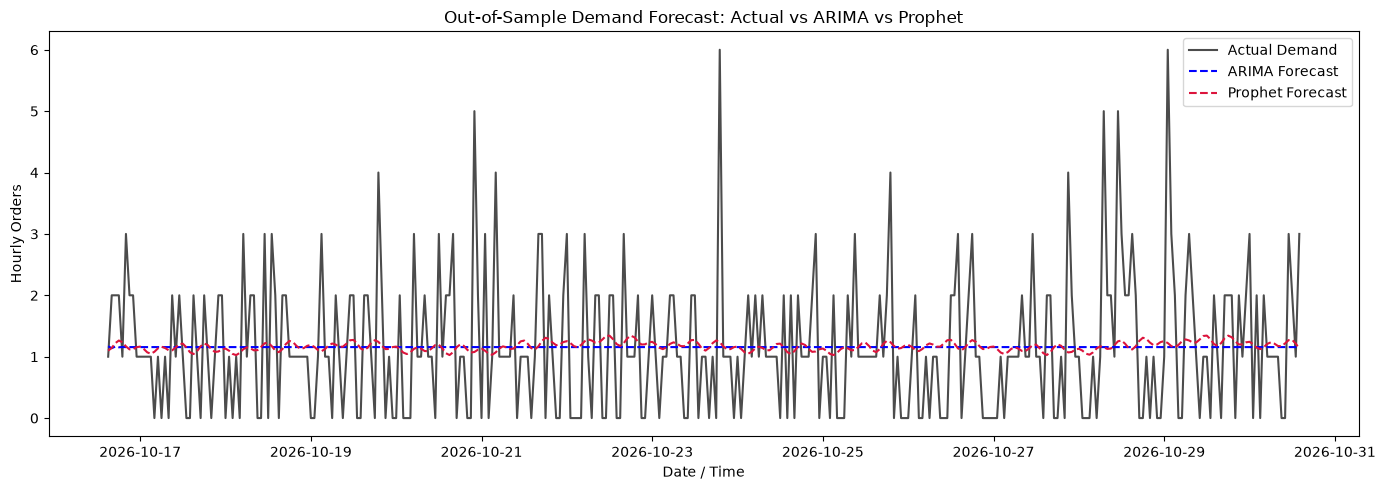

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load Orders Data & Create Complete Hourly Series
orders = pd.read_csv('../data/raw/orders.csv')
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])

# Resample by hour, counting orders
hourly_demand = orders.set_index('order_timestamp').resample('h').agg(
    order_count=('order_id', 'count')
).fillna(0)

# Fill missing timestamps across the entire timeline with 0 demand
hourly_demand = hourly_demand.asfreq('h', fill_value=0)

# Save the prepared hourly demand dataset deliverable
hourly_demand.to_csv('../data/hourly_demand.csv')
print(f"Total hourly records: {len(hourly_demand)}")

# 2. Exploratory Time-Series Analysis
hourly_demand['hour'] = hourly_demand.index.hour
hourly_demand['day_of_week'] = hourly_demand.index.day_name()

plt.figure(figsize=(14, 4))
plt.plot(hourly_demand.index, hourly_demand['order_count'], color='teal', linewidth=0.8)
plt.title('Hourly Order Demand (Historical Timeline)')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
hourly_demand.groupby('hour')['order_count'].mean().plot(kind='bar', ax=axes[0], color='cornflowerblue')
axes[0].set_title('Average Hourly Demand by Time of Day')
axes[0].set_xlabel('Hour of Day (0-23)')
axes[0].set_ylabel('Avg Orders')

order_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly_demand.groupby('day_of_week')['order_count'].mean().reindex(order_days).plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title('Average Hourly Demand by Day of Week')
axes[1].set_xlabel('Day of Week')
plt.tight_layout()
plt.show()

# 3. Time-Series Decomposition (Daily period = 24 hours)
decomp = seasonal_decompose(hourly_demand['order_count'], model='additive', period=24)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.suptitle('Time-Series Decomposition (Trend, Seasonality, Residuals)', y=1.02)
plt.show()

# 4. Stationarity Check (Augmented Dickey-Fuller Test)
adf_result = adfuller(hourly_demand['order_count'].dropna())
print("--- ADF Test Results ---")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4e}")
print(f"Critical Values: {adf_result[4]}")
if adf_result[1] < 0.05:
    print("Conclusion: The series is stationary (p < 0.05). No differencing needed (d=0).")
else:
    print("Conclusion: The series is non-stationary. Differencing (d=1) required.")

# 5. Chronological Train-Test Split (Strictly temporal: Last 14 days as test)
test_hours = 14 * 24  # Last 336 hours
train_df = hourly_demand.iloc[:-test_hours].copy()
test_df = hourly_demand.iloc[-test_hours:].copy()

print(f"Train window: {train_df.index.min()} to {train_df.index.max()} ({len(train_df)} hours)")
print(f"Test window:  {test_df.index.min()} to {test_df.index.max()} ({len(test_df)} hours)")

# 6. ARIMA Model
arima_model = ARIMA(train_df['order_count'], order=(2, 0, 2))
arima_fitted = arima_model.fit()
arima_forecast = arima_fitted.forecast(steps=len(test_df))
arima_forecast.index = test_df.index

# 7. Prophet Model
prophet_train = train_df.reset_index()[['order_timestamp', 'order_count']].rename(
    columns={'order_timestamp': 'ds', 'order_count': 'y'}
)
prophet_test = test_df.reset_index()[['order_timestamp', 'order_count']].rename(
    columns={'order_timestamp': 'ds', 'order_count': 'y'}
)

prophet_model = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=False
)
prophet_model.fit(prophet_train)

future = prophet_test[['ds']].copy()
prophet_forecast_df = prophet_model.predict(future)
prophet_forecast = prophet_forecast_df['yhat'].values

# 8. Model Evaluation & Comparison
def calculate_mape(y_true, y_pred):
    # Add epsilon to denominator to avoid division by zero
    return np.mean(np.abs((y_true - y_pred) / (y_true + 1e-5))) * 100

y_true = test_df['order_count'].values

metrics = [
    {
        'Model': 'ARIMA(2,0,2)',
        'MAE': mean_absolute_error(y_true, arima_forecast),
        'RMSE': np.sqrt(mean_squared_error(y_true, arima_forecast)),
        'MAPE (%)': calculate_mape(y_true, arima_forecast)
    },
    {
        'Model': 'Prophet',
        'MAE': mean_absolute_error(y_true, prophet_forecast),
        'RMSE': np.sqrt(mean_squared_error(y_true, prophet_forecast)),
        'MAPE (%)': calculate_mape(y_true, prophet_forecast)
    }
]

comparison_df = pd.DataFrame(metrics)
print("\n--- Model Comparison on Test Horizon ---")
print(comparison_df.to_string(index=False))

# 9. Forecast Comparison Visualization
plt.figure(figsize=(14, 5))
plt.plot(test_df.index, y_true, label='Actual Demand', color='black', alpha=0.7)
plt.plot(test_df.index, arima_forecast, label='ARIMA Forecast', color='blue', linestyle='--')
plt.plot(test_df.index, prophet_forecast, label='Prophet Forecast', color='crimson', linestyle='--')
plt.title('Out-of-Sample Demand Forecast: Actual vs ARIMA vs Prophet')
plt.xlabel('Date / Time')
plt.ylabel('Hourly Orders')
plt.legend()
plt.tight_layout()
plt.show()